# Bird biodiversity in Martinique, 2014–2025

A first descriptive analysis: read the workbook, clean observations, calculate three indicators and plot annual means. Run all cells from the project root or `notebooks/`.

Each record is a detection entry. A point survey is `(route, date, visit, point)`. We remove exact copies, then sum remaining entries for each species. These are recorded detections, not estimates of population size.

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/raw").exists():
    ROOT = ROOT.parent

for folder in ["data/processed", "results", "figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

source = ROOT / "data/raw/Observations 2012-2025.xlsx"
sheets = pd.read_excel(source, sheet_name=None, header=None)

survey_key = ["route_key", "date", "visit", "point"]
visit_key = ["route_key", "date", "visit"]
metrics = ["richness", "recorded_abundance", "shannon"]
years = range(2014, 2026)


def normalize(values):
    values = values.astype("string").str.strip()
    values = values.str.replace(r"\s+", " ", regex=True)
    return values.str.casefold()

## 1. Load and clean

The observation sheet has three header rows. The eight distance/modality bins and the precomputed totals must not be added together. We use the non-flight total `selected_count`.

Match labels ignoring case and extra spaces. Repair the known `Desmarinière` spelling variant; keep different routes and dates separate. Remove copies using **all original fields**, before discarding observer names and comments.

In [26]:
columns = [
    "observer", "department", "route", "date", "visit",
    "cloud", "rain", "wind", "visibility", "point", "start_time", "species",
    "auditory_25", "visual_25", "auditory_50", "visual_50",
    "auditory_100", "visual_100", "auditory_far", "visual_far", "flight",
    "auditory_total", "visual_total", "selected_count", "total_with_flight",
    "comment",
]

raw = sheets["NOM FRANÇAIS"].iloc[3:].copy()
raw.columns = columns

obs = raw.dropna(how="all").drop_duplicates().copy()
obs["source_row"] = obs.index + 1

for field in ["route", "species", "observer"]:
    obs[field + "_key"] = normalize(obs[field])

obs["route_key"] = obs["route_key"].replace({
    "desmarinière": "desmarinières",
})
obs["date"] = pd.to_datetime(obs["date"], errors="coerce")
obs["year"] = obs["date"].dt.year

In [27]:
# Keep track of values that cannot be read as numbers.
numeric_columns = ["visit", "point"] + columns[12:25]
original_numbers = obs[numeric_columns]
converted_numbers = original_numbers.apply(pd.to_numeric, errors="coerce")
malformed = original_numbers.notna() & converted_numbers.isna()
obs[numeric_columns] = converted_numbers

valid_key = obs[survey_key].notna().all(axis=1)
in_period = obs["year"].between(2014, 2025)
obs = obs.loc[valid_key & in_period].copy()

integer_columns = ["year", "visit", "point"]
obs[integer_columns] = obs[integer_columns].astype(int)

assert obs["point"].between(1, 10).all()
assert obs["visit"].isin([1, 2]).all()
print(f"Source: {len(raw):,} records; retained: {len(obs):,}")

Source: 114,495 records; retained: 112,252


## 2. Species and habitat references

Join species names and habitats with many-to-one checks. Habitat depends on both route and point. The reference contains two known typos (`Pigeon à coup rouge`, `SIPI`) and a duplicate species row.

In [28]:
species = sheets["ESPECES"].iloc[:, 2:5].drop_duplicates().copy()
species.columns = ["reference_species", "scientific_name", "status"]
species["species_key"] = normalize(species["reference_species"])
species["species_key"] = species["species_key"].replace({
    "pigeon à coup rouge": "pigeon à cou rouge",
})

habitat = sheets["GPS-MILIEU"].iloc[2:, 2:8].copy()
habitat.columns = [
    "reference_route", "x_utm20", "y_utm20",
    "habitat", "route_code", "point_code",
]
habitat["route_key"] = normalize(habitat["reference_route"])

point_codes = habitat["point_code"].replace({"SIPI": "S1P1"})
point_numbers = point_codes.str.extract(r"P(\d+)$")[0]
habitat["point"] = point_numbers.astype(int)

obs = obs.merge(
    species,
    on="species_key",
    how="left",
    validate="many_to_one",
)
obs = obs.merge(
    habitat,
    on=["route_key", "point"],
    how="left",
    validate="many_to_one",
)

## 3. Count quality

Missing, negative, fractional or conflicting counts invalidate the whole point survey. Empty detail bins count as zero only when checking Excel totals. Unidentified groups contribute to abundance, but positive unidentified counts make richness and Shannon unavailable. `RAS` means zero detections.

In [29]:
detail_columns = columns[12:20]
subtotal_columns = ["auditory_total", "visual_total"]
components = obs[detail_columns + subtotal_columns]

negative_component = components < 0
fractional_component = (components % 1 != 0) & components.notna()
bad_component = (negative_component | fractional_component).any(axis=1)

selected_count = obs["selected_count"]
detail_sum = obs[detail_columns].sum(axis=1)
bad_detail = ~np.isclose(selected_count, detail_sum)

complete_subtotals = obs[subtotal_columns].notna().all(axis=1)
subtotal_sum = obs["auditory_total"] + obs["visual_total"]
bad_subtotal = complete_subtotals & ~np.isclose(selected_count, subtotal_sum)

bad_total = (
    selected_count.isna()
    | (selected_count < 0)
    | (selected_count % 1 != 0)
)

# Ignore whitespace-only Excel bins when checking parsing errors.
original_details = raw.loc[malformed.index, detail_columns]
nonblank = original_details.apply(
    lambda values: values.astype("string").str.strip().ne("")
)
malformed_details = (malformed[detail_columns] & nonblank).any(axis=1)
bad_source_rows = malformed.index[malformed_details] + 1

obs["count_problem"] = (
    bad_total
    | bad_component
    | bad_detail
    | bad_subtotal
    | obs["source_row"].isin(bad_source_rows)
)

display_columns = ["source_row", "species", "selected_count"]
display(obs.loc[obs["count_problem"], display_columns])

,source_row,species,selected_count
5081,5094,Héron vert,0.0
5082,5095,Quiscale merle,0.0
5083,5096,Sucrier à ventre jaune,0.0
5084,5097,Elénie siffleuse,0.0
5085,5098,Merle à lunettes,0.0
...,...,...,...
102472,104710,Trochilidae,4.0
102477,104715,Solitaire siffleur,5.0
102481,104719,Moqueur grivotte,3.0
102486,104724,Elénie siffleuse,4.0


In [30]:
unresolved_taxa = {
    "trochilidae", "estrildidae", "apodidae", "hirundinidae", "columbidae",
    "limicole", "martinet", "mimidae", "lonchura sp.", "sterne sp",
    "capucin sp", "fauconidae", "gallinacées", "moqueur sp.", "anatidae",
    "egretta sp.", "falconidé", "héron ?",
}

obs["unresolved_positive"] = (
    obs["species_key"].isin(unresolved_taxa)
    & (obs["selected_count"] > 0)
)

zero_marker = obs["species_key"] == "ras"
assert obs.loc[zero_marker, "selected_count"].eq(0).all()

## 4. Point-survey indicators

For species counts $n_s$, abundance is $N=\sum_s n_s$, richness is the number of positive species counts, and Shannon diversity is $H=-\sum_s p_s\log p_s$, where $p_s=n_s/N$.

For valid zero-count surveys, abundance and richness are zero; Shannon is undefined. Missing surveys are never inserted as zero. Observer/time conflicts and repeated species are flagged; remaining same-species records are provisionally additive and may include repeated detections of the same bird.

In [31]:
# One row per point survey, with its quality flags.
points = obs.groupby(survey_key).agg(
    year=("year", "first"),
    habitat=("habitat", "first"),
    count_problem=("count_problem", "any"),
    unresolved_positive=("unresolved_positive", "any"),
    observer_labels=("observer_key", "nunique"),
    start_times=("start_time", "nunique"),
)

# Sum detection entries for each species within each survey.
birds = obs.loc[~zero_marker]
species_counts = birds.groupby(survey_key + ["species_key"])
counts = species_counts["selected_count"].sum().unstack(fill_value=0)
counts = counts.reindex(points.index, fill_value=0)

repeated_species = obs.duplicated(survey_key + ["species_key"], keep=False)
survey_groups = [obs[field] for field in survey_key]
points["repeated_species"] = repeated_species.groupby(survey_groups).any()
points["metadata_conflict"] = (
    (points["observer_labels"] > 1)
    | (points["start_times"] > 1)
)

In [32]:
# Abundance counts detections; richness counts species with positive counts.
points["recorded_abundance"] = counts.sum(axis=1)
points["richness"] = (counts > 0).sum(axis=1)

# Shannon: H = -sum(p * log(p)), using only positive proportions.
abundance = points["recorded_abundance"].replace(0, np.nan)
proportions = counts.div(abundance, axis=0)
positive_proportions = proportions.where(proportions > 0)
shannon_terms = proportions * np.log(positive_proportions)
points["shannon"] = -shannon_terms.sum(axis=1, min_count=1)

# Invalid counts affect every indicator; unidentified birds affect diversity.
points.loc[points["count_problem"], metrics] = np.nan
points.loc[points["unresolved_positive"], ["richness", "shannon"]] = np.nan

points = points.reset_index()
display(points[metrics].describe())

,richness,recorded_abundance,shannon
count,13077.000000,14076.000000,13074.000000
mean,7.759043,17.199844,1.810549
std,2.667252,10.881662,0.390437
min,0.000000,0.000000,-0.000000
25%,6.000000,10.000000,1.581094
50%,8.000000,15.000000,1.863680
75%,10.000000,22.000000,2.084430
max,18.000000,210.000000,2.685771


## 5. Sampling effort and annual means

Average valid surveys within each route/year, then average those route means within each year. Each contributing route receives equal weight. Counts of valid surveys and contributing routes accompany the estimates.

Effort includes all represented surveys, even those with invalid indicators. Fewer than ten points marks an incomplete route visit in this extract; it does not prove that the other points were never visited.

In [33]:
route_visits = points.groupby(visit_key)["point"].nunique()
route_visits = route_visits.rename("n_points").reset_index()
route_visits["year"] = route_visits["date"].dt.year
route_visits["incomplete"] = route_visits["n_points"] < 10

effort = points.groupby("year").agg(
    point_surveys=("point", "size"),
    routes=("route_key", "nunique"),
)
effort["observer_labels"] = obs.groupby("year")["observer_key"].nunique()

visit_effort = route_visits.groupby("year").agg(
    route_visits=("n_points", "size"),
    incomplete_visits=("incomplete", "sum"),
)
effort = effort.join(visit_effort).reindex(years)
display(effort)

,point_surveys,routes,observer_labels,route_visits,incomplete_visits
year,,,,,
2014,779,41,24,80,4
2015,1060,53,26,111,8
2016,1162,59,28,118,4
2017,1169,60,27,121,7
2018,1265,64,23,130,7
2019,1247,64,21,126,3
2020,1158,63,15,116,1
2021,1256,63,12,128,6
2022,1259,63,15,127,3


In [34]:
# First average surveys within a route, then average routes within a year.
route_year = points.groupby(["route_key", "year"])[metrics].mean()
annual = route_year.groupby("year").mean().reindex(years)

contributing_routes = route_year.groupby("year")[metrics].count()
valid_surveys = points.groupby("year")[metrics].count()

annual = annual.join(contributing_routes.add_suffix("_routes"))
annual = annual.join(valid_surveys.add_suffix("_valid_surveys"))
display(annual.round(4))

,richness,recorded_abundance,shannon,richness_routes,recorded_abundance_routes,shannon_routes,richness_valid_surveys,recorded_abundance_valid_surveys,shannon_valid_surveys
year,,,,,,,,,
2014,6.4322,14.0114,1.6665,40,40,39,655,740,654
2015,7.3533,16.2893,1.7677,53,53,53,900,1059,900
2016,7.7539,16.5122,1.8299,59,59,59,994,1155,993
2017,7.7253,17.5533,1.8136,60,60,60,1040,1165,1040
2018,7.4403,15.8406,1.7679,64,64,64,1163,1261,1163
2019,7.5680,16.9029,1.7796,64,64,64,1159,1241,1159
2020,8.3918,18.7225,1.8948,63,63,63,1131,1142,1131
2021,8.3256,19.0750,1.8738,63,63,63,1218,1252,1218
2022,8.3034,19.2121,1.8760,63,63,63,1243,1255,1243


## 6. Save and plot

Exports omit observer names, normalized observer labels and free-text comments. The workbook is read-only. The three figures and five tables below are regenerated on every run.

In [35]:
# Export analysis data without names or free-text comments.
private_columns = ["observer", "observer_key", "comment"]
observations_export = obs.drop(columns=private_columns)

observations_export.to_csv(
    ROOT / "data/processed/observations_clean.csv",
    index=False,
)
points.to_csv(ROOT / "data/processed/point_surveys.csv", index=False)
route_year.to_csv(ROOT / "data/processed/route_year_indicators.csv")
annual.to_csv(ROOT / "results/annual_indicators.csv")
effort.to_csv(ROOT / "results/annual_sampling_effort.csv")

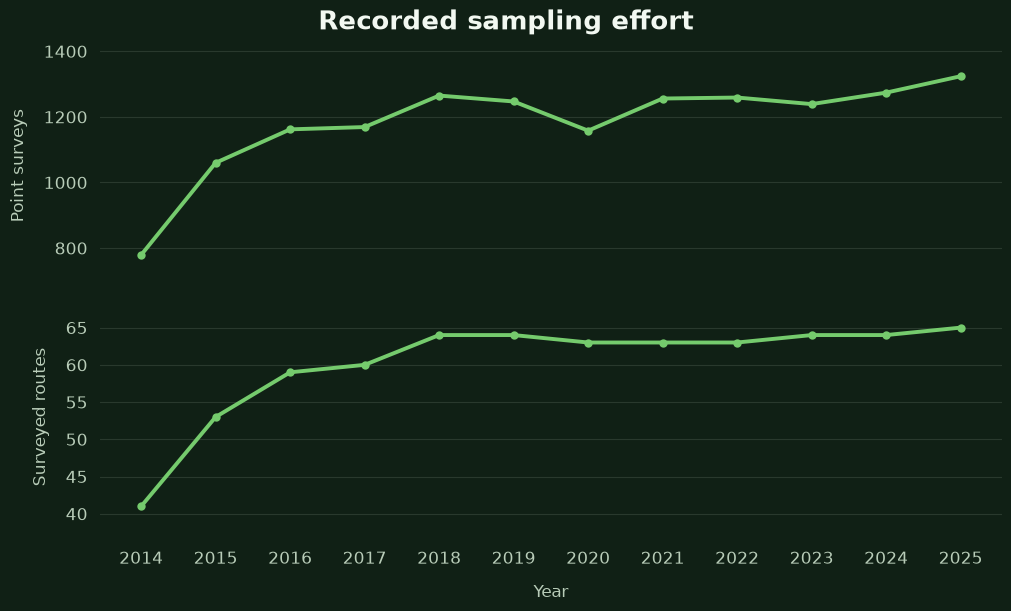

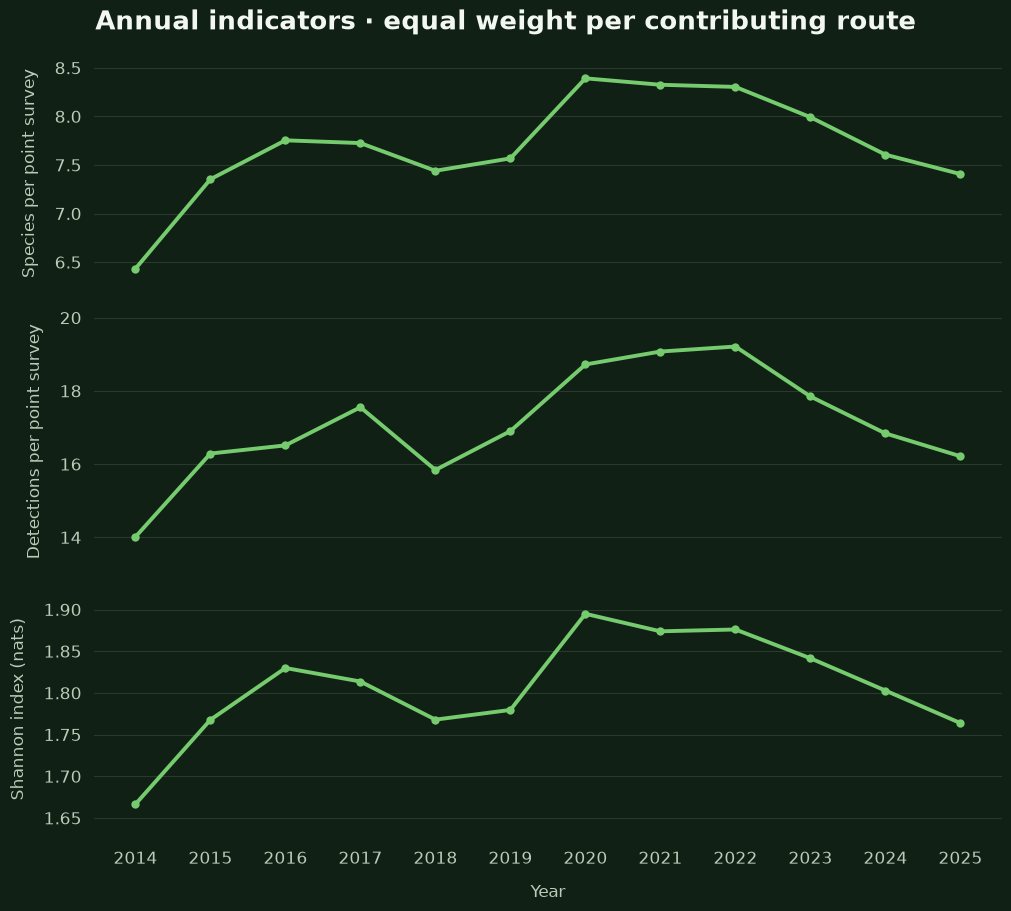

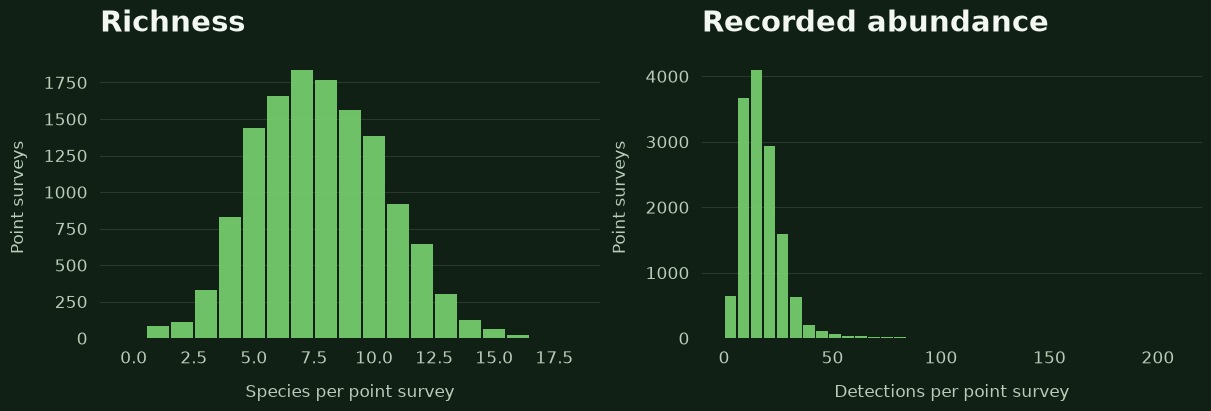

In [36]:
# Share the presentation style and add a background for notebook viewing.
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.plot_figures import GREEN, configure, style_axis

configure(background="#102015")

plots = [
    (effort, ["point_surveys", "routes"], "sampling_effort",
     "Recorded sampling effort"),
    (annual, metrics, "annual_indicators",
     "Annual indicators · equal weight per contributing route"),
]
labels = {
    "point_surveys": "Point surveys",
    "routes": "Surveyed routes",
    "richness": "Species per point survey",
    "recorded_abundance": "Detections per point survey",
    "shannon": "Shannon index (nats)",
}

for table, fields, filename, title in plots:
    fig, axes = plt.subplots(
        len(fields), 1,
        figsize=(10, 3 * len(fields)),
        sharex=True,
        layout="constrained",
    )
    fig.suptitle(title, fontsize=19, fontweight="bold")

    for ax, field in zip(axes, fields):
        ax.plot(
            table.index, table[field],
            color=GREEN, linewidth=2.8,
            marker="o", markersize=6, markeredgewidth=0,
        )
        ax.set_ylabel(labels[field])
        ax.margins(y=0.18)
        style_axis(ax)

    axes[-1].set(xticks=list(years), xlabel="Year")
    fig.savefig(ROOT / f"figures/{filename}.png", dpi=180)
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, field in zip(axes, ["richness", "recorded_abundance"]):
    values = points[field].dropna()
    bins = 35
    if field == "richness":
        bins = [n - 0.5 for n in range(int(values.max()) + 2)]

    ax.hist(values, bins=bins, color=GREEN, alpha=0.95, rwidth=0.9)
    ax.set_title(field.replace("_", " ").capitalize(), loc="left")
    ax.set(xlabel=labels[field], ylabel="Point surveys")
    style_axis(ax)

fig.savefig(ROOT / "figures/indicator_distributions.png", dpi=180)
plt.show()

## Code style references

The notebook follows the step-by-step presentation of the course examples: named intermediate results, short comments, and separate cells for each calculation.

- [Inference estimators: worked solution](https://github.com/stephane-rivaud/Applied-Statistics/blob/main/labs/03-inference-estimators/solution.ipynb)
- [Model fitting: assignment](https://github.com/stephane-rivaud/Applied-Statistics/blob/main/labs/06-model-fitting/assignment.ipynb)

## What these results mean

These curves describe recorded detections in sampled routes. Changes in coverage, unresolved identifications, conflicting counts and repeated detections can affect annual comparisons. Flags in the point table identify surveys needing closer inspection.

This is the descriptive first stage. Confidence intervals, formal trends and selected-species analysis still need to be added for the full assignment. For uncertainty estimates, resample whole routes with their histories, then repeat both averaging steps.